<img src="https://drive.google.com/uc?export=view&id=1XMSQvqGXdYM0McNCTafguLUn1uiL8zu_"  width="1500px" height="300px">




# <center> **13. An extra application on Deep neuronal networks** </center>

From DNN lecture seen on previous class, try to approach this algorithms in other application: audio recognition.

##  **Outline**
1. [**DL:Understanding audio settings**](#eje1)
2. [**DL:audio from raw analysis**](#eje2)
3. [**DL:audio from melspectrograms**](#eje3)

In [ ]:
#@title **MONTAR EL DRIVE** { display-mode: "form" }
import os
from google.colab import drive

path_ai = "course-AI/ai-uis-student" #@param {type:"string"}
path = "/content/drive/My Drive/" + path_ai
drive.mount('/content/drive')
os.chdir(path)
print(os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/My Drive/course-AI/ai-uis-student


In [4]:
#@title **1. Professor:** MONTAR EL DRIVE  (If you are in in colab){ display-mode: "form" }
import os
from google.colab import drive
drive.mount('/content/drive')

os.chdir('/content/drive/My Drive/main/academic/courses/2018-UIS-AritfitialInteligence/Data/')
print(os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/My Drive/main/academic/courses/2018-UIS-AritfitialInteligence/Data


In [3]:
#@title 2. LOAD LIB { display-mode: "form" }
#@markdown Here is important to change to GPU
import os
import tensorflow as tf
from tensorflow import keras
print(tf.__version__)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#!pip install librosa

2.21.0


A typical library to read and rpocess audio is `librosa`. We firstly install library and then we can start to work.

`!pip install librosa`

# **1. DL:Understanding audio settings** <a name="eje1"></a>

<img src="https://gitlab.com/bivl2ab/academico/cursos-uis/ai/ai-uis-student/raw/master/imgs/speech.jpeg" alt="Drawing" style="width:1700px;">

## **1.1 Free Spoken Digit Dataset (FSDD): The speech MNIST**

A simple audio/speech dataset consisting of recordings of spoken digits in wav files at 8kHz. The recordings are trimmed so that they have near minimal silence at the beginnings and ends [Source](https://github.com/Jakobovski/free-spoken-digit-dataset)

### Dataset description

- 4 speakers
- 2.000 recordings (50 of each digit per speaker)
- English pronunciations

An example of the dataset: `{digitLabel}_{speakerName}_{index}.wav` Example: `7_jackson_32.wav`

A typical library to read and rpocess audio is `librosa`. We firstly install library and then we can start to work`

In [19]:
#@title **code** reproduce an audio example
file_name = "7_jackson_40.wav" #@param {type:"string"}
#0_theo_4.wav
import IPython.display as ipd
ipd.Audio('fsdd/'+file_name)

sr: 8000
wav shape: (3532,)


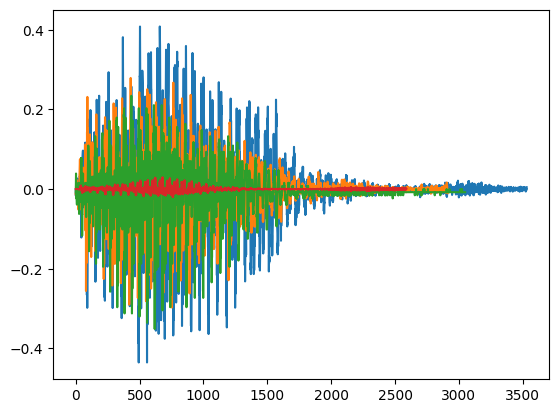

In [26]:
#@title **code** Working with librosa
import librosa
wav, sr = librosa.load('fsdd/8_jackson_40.wav', sr=None)
wav2, sr = librosa.load('fsdd/8_jackson_10.wav', sr=None)
wav3, sr = librosa.load('fsdd/8_nicolas_10.wav', sr=None)
wav4, sr = librosa.load('fsdd/8_theo_10.wav', sr=None)
print( 'sr:', sr)
print( 'wav shape:', wav.shape)

plt.plot(wav);
plt.plot(wav2);
plt.plot(wav3);
plt.plot(wav4);

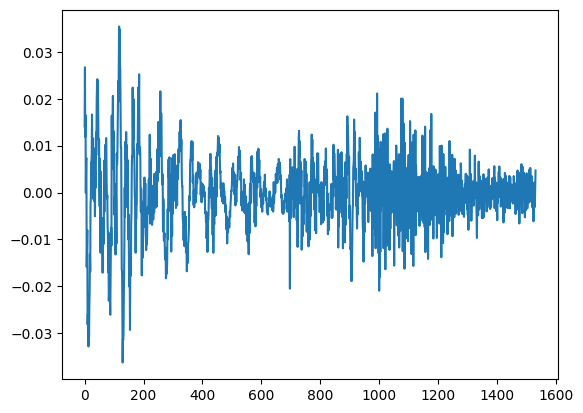

In [21]:
#@title **code** To see more specific interval of signal
plt.plot(wav[2000:5000])

# **3. DL:audio from melspectrograms** <a name="eje3"></a>

- Raw signals are not good candidate to represent audio. So, we can compute a natural feature of this sign that is the FFT

See an example

(1025, 7)
(7175,)


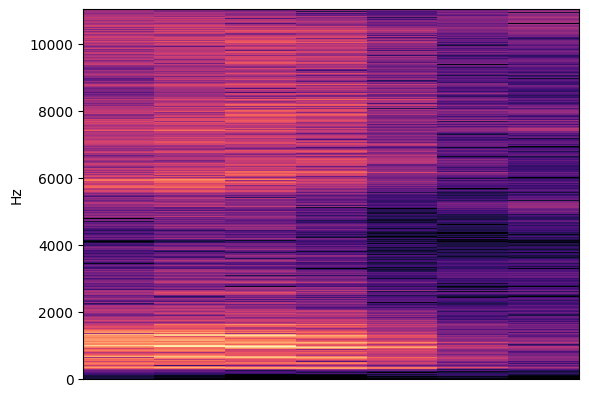

In [22]:
#@title **code** To compute FFT
import librosa.display as dis
D = librosa.amplitude_to_db(np.abs(librosa.stft(wav)), ref=np.max)
print( D.shape)
print( D.reshape(D.shape[0]*D.shape[1]).shape)
dis.specshow(D, y_axis='linear');

In audio one of the more relevant and compact features is the `melspectrogram` [wiki](https://es.wikipedia.org/wiki/MFCC)

(128, 7)


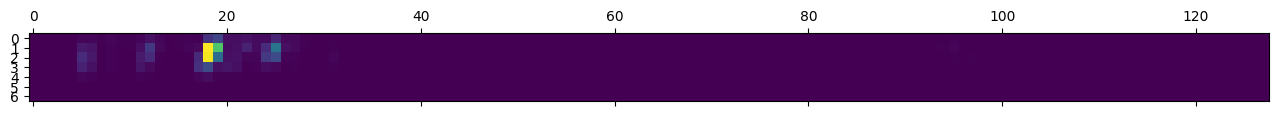

In [23]:
#@title **code** To compute melspectrogram
SP = librosa.feature.melspectrogram(y=wav, sr=sr)
print( SP.shape)
plt.matshow(SP.T)

## **To load audio data**

- Read the FSDD audio dataset, using `librosa` library
  - Built the $\mathbf{X}$ $\in$ $\mathbb{R}^{n \times m}$ matrix. The $n$ rows are the examples (20000) and $m$ colums is the dimension of each file.
  - Built the $\mathbf{y} \in \mathbb{R}^{n}$ corresponding to classes labels.
    
    
**Pay attention that all files dont have the same dimension.** Then, we add zeros to obtain files with same size. This process is named `padding`    
- For so, you can use next function.

In [27]:
#@title **code** Padding function
def func_padding(wav, pad_size=2000):
    if wav.shape[0] > pad_size:
        return wav[0: pad_size]
    else:
        return np.hstack((wav, np.zeros(pad_size - wav.shape[0])))

In [32]:
#@title **code** To compute X, y
def get_Xy_Features(DATA_DIR = 'fsdd/', pad_size=500):

    X = []
    y = []

    for fname in os.listdir(DATA_DIR):
        struct = fname.split('_')
        digit = struct[0]
        if (digit == '0') or (digit == '1'):
          wav, sr = librosa.load(DATA_DIR + fname)
          D = librosa.feature.melspectrogram(y=wav)
          padded = func_padding(D.reshape(D.shape[0]*D.shape[1]), pad_size)
          X.append(padded)
          y.append(digit)
    return np.vstack(X), np.array(y)



In [33]:
#@title **code** To compute train-test
from sklearn.model_selection import train_test_split
X, y = get_Xy_Features(DATA_DIR = 'fsdd/')
print( 'X:', X.shape)
print( 'y:', y.shape)
test_size = 0.1
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size)
print(X_train.shape, y_train.shape)
print(X_train[0].shape)

X: (400, 500)
y: (400,)
(360, 500) (360,)
(500,)


In [34]:
#@title **code** One-hot encoding
y_train_ohe = tf.keras.utils.to_categorical(y_train, num_classes=2)
y_test_ohe = tf.keras.utils.to_categorical(y_test, num_classes=2)
print(y_train_ohe.shape, y_test_ohe.shape)

(360, 2) (40, 2)


In [35]:
#@title **code** DNN model
model = tf.keras.Sequential([
    tf.keras.layers.Flatten( input_shape= X_train[0].shape),
    tf.keras.layers.Dense(128, activation=tf.nn.relu),
    tf.keras.layers.Dense(2, activation=tf.nn.softmax)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 423ms/step - accuracy: 0.4861 - loss: 3.4759 - val_accuracy: 0.6000 - val_loss: 3.1809
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.6583 - loss: 2.2164 - val_accuracy: 0.7250 - val_loss: 2.2288
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.7417 - loss: 1.8977 - val_accuracy: 0.7000 - val_loss: 2.5232
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.7722 - loss: 1.6105 - val_accuracy: 0.7000 - val_loss: 2.4593
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.7972 - loss: 1.3634 - val_accuracy: 0.7000 - val_loss: 2.7272
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.8083 - loss: 1.1597 - val_accuracy: 0.7250 - val_loss: 2.6049
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.8250 - loss: 1.0266 - val_accuracy: 0.7000 - val_loss: 2.1890
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.8306 - loss: 0.7721 - val_accuracy: 0.6750 - val_loss: 2.2823

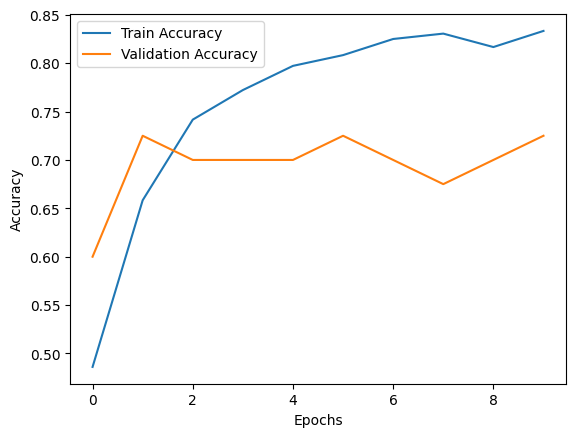

In [36]:
#@title **code** To compile and fit the model
model.compile(optimizer=tf.keras.optimizers.Adam(),
              loss='binary_crossentropy',
              metrics=['accuracy'])
history = model.fit(X_train,
          y_train_ohe,
          epochs=10,
          batch_size=100,
          validation_data=(X_test, y_test_ohe))

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

In [37]:
#@title **code** To evaluate the model
test_loss, test_acc = model.evaluate(X_test, y_test_ohe, verbose=False)

print( 'Test accuracy:', test_acc, " test_loss: ", test_loss)

Test accuracy: 0.7250000238418579  test_loss:  1.4877245426177979


<img src="https://gitlab.com/bivl2ab/academico/cursos-uis/ai/ai-2-uis-student/-/raw/master/imgs/icon1.png" width="200">

- In this particular dataset, it is better to perform train-test split according to the actors, that its to say:
    - Three actors for training
    - The other actor for test.
Built a function that receive a list with three actors for training and the actor for test and return the respectives $( \mathbf{X_{tr}}, \mathbf{X_{te}}, \mathbf{y_{tr}}, \mathbf{y_{te}} )$


In [ ]:
#@title **code student**
DATA_DIR = '../data/fsdd/'
def fun_ByActor(list_train = ['jackson','theo','yweweler'], pad_size=1000):






    return np.vstack(X_tr),np.vstack(X_te), np.array(y_tr),np.array(y_te)

In [ ]:
#@title **code student**


X_tr, X_te, y_tr, y_te = fun_ByActor(['jackson','theo','yweweler'], 1000)

In [ ]:
#@title **code student**
print(X_tr.shape, X_te.shape, y_tr.shape, y_te.shape)

Check the previous configuration.
 - What about the performance?

In [ ]:
#@title **code student**
model = keras.models.Sequential([




])
model.summary()

In [ ]:
#@title **code student**
model.compile(   )

In [ ]:
#@title **code student**
history = model.fit(X_tr,
          y_tr,
          epochs=10,
          batch_size=1000,
          validation_data=(X_te, y_te))

plt.plot(history.history['acc'], label='Train Accuracy')
plt.plot(history.history['val_acc'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

In [ ]:
#@title **code student**
test_loss, test_acc = model.evaluate(X_te, y_te, verbose=False)

print('Test accuracy:', test_acc, " test_loss: ", test_loss)

<img src="https://gitlab.com/bivl2ab/academico/cursos-uis/cv/cv-uis-student/raw/master/imgs/bannerThanks.jpg" style="width:1000px;">
